# 05 Water resources and water stress

**Questions**
1. Which African countries face the greatest water stress?
2. How does agricultural dependence relate to water pressure?
3. Are water risks increasing over time?

**What I expect going in**
- **H1** Water stress is highest in North Africa and the Sahel.
- **H2** Countries where agriculture takes a larger share of withdrawals face higher water stress.

**Read before interpreting:** AQUASTAT water data has few measured years per country, and many values are repeated or modelled. This notebook treats water stress as a cross-section and answers the "increasing over time" question only where the data has enough distinct values. Internal renewable water excludes rivers flowing in from other countries (Nile, Zambezi, Congo), so downstream countries look worse than their actual supply.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "05 water"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. How much water data is there?

In [2]:
wids = [i for i in ("D01", "D02", "D04", "D05", "D06", "D10", "D11") if i in panel]
sparse = pd.DataFrame({i: af[af["indicator_id"] == i].groupby("iso3")["value"].nunique() for i in wids}).reindex(AFRICA)
print("Distinct values per country, 2000 onward (a proxy for how many real measurements exist):")
sparse.describe().loc[["count", "min", "50%", "max"]]

Distinct values per country, 2000 onward (a proxy for how many real measurements exist):


,D01,D02,D04,D05,D06,D10,D11
count,54.000,53.000,53.000,53.000,54.000,30.000,54.000
min,1.000,1.000,11.000,1.000,1.000,22.000,13.000
50%,16.000,16.000,33.000,16.000,16.000,25.000,25.000
max,33.000,33.000,33.000,33.000,33.000,25.000,25.000


**Water data has more distinct values than expected, but many are modelled.**

- The median country has 16 distinct water stress values since 1990, and 606 water stress values carry an interpolation flag from 01.
- Safely managed drinking water is reported for only 30 of 54 countries.

## 2. Water stress ranking (H1)

,iso3,country,year,value,au_region
75437,LBY,Libya,2022,817.143,North
74965,DZA,Algeria,2022,144.815,North
74998,EGY,Egypt,2022,141.166,North
75830,SDN,Sudan,2022,118.656,East
76102,TUN,Tunisia,2022,98.113,North
76003,SWZ,Eswatini,2022,77.560,Southern
76230,ZAF,South Africa,2022,67.595,Southern
74867,CPV,Cabo Verde,2022,59.684,West
75503,MAR,Morocco,2022,50.751,North
76294,ZWE,Zimbabwe,2022,46.092,Southern


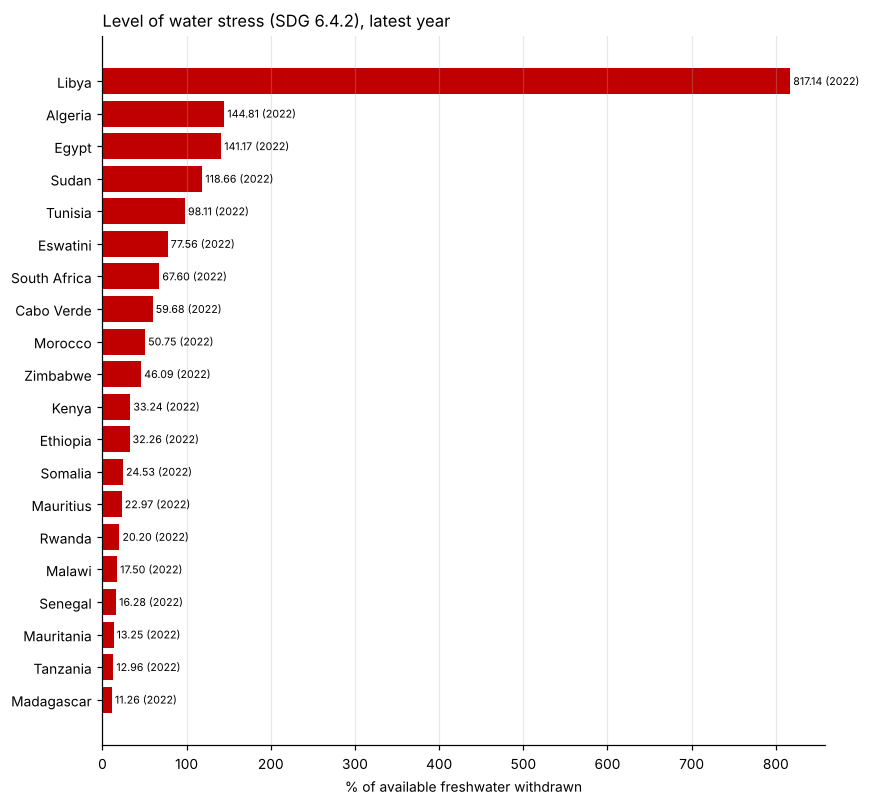

Median water stress by AU region (%):


au_region
North      119.640
East        12.963
West         5.088
Southern     2.701
Central      0.502
Name: value, dtype: float64

Lowest internal renewable water per person (cubic metres):


,iso3,country,year,value
72995,EGY,Egypt,2022,8.880
73891,SDN,Sudan,2022,80.999
73649,MRT,Mauritania,2022,82.041
73451,LBY,Libya,2022,96.902
73781,NER,Niger,2022,138.274
72962,DZA,Algeria,2022,247.310
72929,DJI,Djibouti,2022,263.830
73990,SOM,Somalia,2022,337.043
74199,TUN,Tunisia,2022,346.141
73385,KEN,Kenya,2022,381.550


In [3]:
if "D05" in panel:
    ws = latest("D05", max_age=8)
    ws["au_region"] = ws["iso3"].map(cty["au_region"])
    display(ws.head(12))
    barh(ws, "value", "Level of water stress (SDG 6.4.2), latest year", "% of available freshwater withdrawn", "water stress ranking.png", n=20, color=RED)
    print("Median water stress by AU region (%):")
    display(ws.groupby("au_region")["value"].median().sort_values(ascending=False))
if "D04" in panel:
    pcw = latest("D04", max_age=10).sort_values("value")
    print("Lowest internal renewable water per person (cubic metres):")
    display(pcw.head(10))

**H1 supported: water stress is extreme in North Africa and Sudan, and almost absent in Central Africa.**

- Libya withdraws 817% of its renewable freshwater, Algeria 145%, Egypt 141% and Sudan 119%. Values above 100% mean withdrawals exceed the renewable supply.
- In Southern Africa, Eswatini (78%), South Africa (68%) and Zimbabwe (46%) stand out.
- Median stress is 120% in North Africa against 0.5% in Central Africa.
- Egypt has only 9 cubic metres of internal renewable water per person. The measure excludes water flowing in from other countries, such as the Nile, so it understates Egypt's actual supply.

## 3. Agricultural dependence and water pressure (H2)

D06 vs D05: Spearman rho = 0.67 (p = 0.000), n = 53
G08 vs D05: Spearman rho = -0.09 (p = 0.524), n = 53


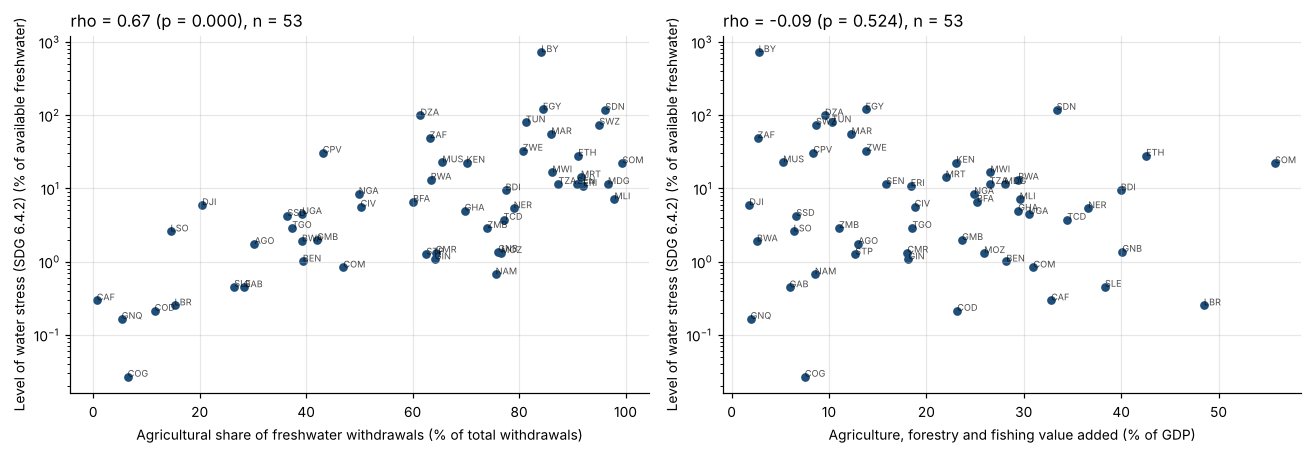

In [4]:
pairs = [(x, "D05") for x in ("D06", "G08") if x in panel and "D05" in panel]
fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 4.2)) if pairs else (None, [])
for a, (x, y) in zip(np.atleast_1d(axes), pairs):
    s = afp.groupby("iso3")[[x, y]].mean().dropna()
    rho, p = stats.spearmanr(s[x], s[y])
    a.scatter(s[x], s[y], color=BLUE, s=22); a.set_yscale("log")
    for iso, r in s.iterrows():
        a.annotate(iso, (r[x], r[y]), fontsize=6, alpha=0.7)
    print(f"{x} vs {y}: Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(s)}")
    a.set_xlabel(label(x)); a.set_ylabel(label(y)); a.set_title(f"rho = {rho:.2f} (p = {p:.3f}), n = {len(s)}", loc="left")
if pairs:
    plt.tight_layout(); plt.savefig(OUT / "agriculture vs water stress.png", dpi=150); plt.show()

**H2 supported on the right measure: water stress rises with agriculture's share of withdrawals (rho = 0.67, p < 0.001), not with agriculture's share of GDP (rho = -0.09, p = 0.52).**

Irrigation intensity, not agricultural dependence in general, drives water pressure.

## 4. Is water stress rising? Only where the data can say

In [5]:
if "D05" in panel:
    rows = []
    for iso, g in af[af["indicator_id"] == "D05"].groupby("iso3"):
        g = g.sort_values("year")
        if g["value"].nunique() >= 5 and g["year"].nunique() >= 10:
            slope, _, r, p, _ = stats.linregress(g["year"], g["value"])
            rows.append([name.get(iso, iso), g["year"].min(), g["year"].max(), g["value"].nunique(), slope, p])
        else:
            rows.append([name.get(iso, iso), g["year"].min(), g["year"].max(), g["value"].nunique(), np.nan, np.nan])
    trend = pd.DataFrame(rows, columns=["country", "from", "to", "distinct_values", "slope_pp_per_year", "p"])
    ok = trend.dropna()
    print(f"Enough distinct values to test a trend: {len(ok)} of {len(trend)} countries; rising significantly (p < 0.05): {((ok['slope_pp_per_year'] > 0) & (ok['p'] < 0.05)).sum()}")
    display(trend.sort_values("slope_pp_per_year", ascending=False).head(15))

Enough distinct values to test a trend: 50 of 53 countries; rising significantly (p < 0.05): 41


,country,from,to,distinct_values,slope_pp_per_year,p
25,Libya,1990,2022,23,7.172,0.000
13,Algeria,1990,2022,33,2.803,0.000
11,Cabo Verde,2001,2022,22,2.639,0.000
14,Egypt,1990,2022,28,1.262,0.000
47,Tunisia,1990,2022,31,0.881,0.000
50,South Africa,1990,2022,33,0.830,0.000
37,Rwanda,2000,2022,20,0.764,0.000
23,Kenya,1990,2022,27,0.703,0.000
16,Ethiopia,2002,2022,16,0.694,0.000
52,Zimbabwe,1990,2022,31,0.528,0.000


**Water stress has risen significantly in 41 of the 50 countries where a trend can be tested, fastest in North Africa.**

- Libya's stress rose by 7.2 points a year, Algeria's by 2.8 and Egypt's by 1.3.
- Caution: many of these series are interpolated or modelled (see 01). Read this as a direction, not a precise rate.

## 5. Drinking water access

In [6]:
acc = {i: change(i) for i in ("D11", "D10") if i in panel}
for i, d in acc.items():
    print(f"{label(i)}: {len(d)} countries; median latest {d['latest'].median():.1f}; median change {d['abs_change'].median():+.1f} points")
    display(d.sort_values("latest").head(10))

People using at least basic drinking water (% of population): 52 countries; median latest 73.8; median change +14.7 points


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
COD,DR Congo,2024,35.681,37.519,-1.837,-4.897
CAF,Central African Republic,2024,36.504,57.831,-21.327,-36.878
BFA,Burkina Faso,2024,49.999,55.694,-5.696,-10.227
ERI,Eritrea,2016,51.850,47.125,4.725,10.025
TCD,Chad,2024,52.209,39.215,12.994,33.137
NER,Niger,2024,53.427,37.339,16.088,43.086
MDG,Madagascar,2024,55.339,37.136,18.203,NaN
ETH,Ethiopia,2024,55.596,20.285,35.311,NaN
RWA,Rwanda,2024,61.392,48.376,13.017,26.907


People using safely managed drinking water (% of population): 30 countries; median latest 30.6; median change +10.2 points


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
CAF,Central African Republic,2024,6.217,8.396,-2.179,-25.949
TCD,Chad,2024,6.341,5.554,0.787,14.168
SLE,Sierra Leone,2024,10.895,5.306,5.589,NaN
COD,DR Congo,2024,11.873,12.211,-0.338,-2.772
ETH,Ethiopia,2024,13.547,5.507,8.040,145.995
BEN,Benin,2024,17.697,14.318,3.379,23.600
UGA,Uganda,2024,18.097,3.102,14.995,NaN
MWI,Malawi,2024,18.182,7.318,10.864,148.450
TGO,Togo,2024,20.523,10.441,10.082,96.564


**Basic water access improved by a median 14.7 points, but DR Congo and Central African Republic went backwards.**

- The median country has 73.8% of its population with at least basic drinking water.
- DR Congo (35.7%) and Central African Republic (36.5%) are lowest, and both are below their 2000 to 2002 levels.
- Only about 31% of people in the median reporting country have safely managed water.

## 6. Save tables

In [7]:
save_excel("water results.xlsx", {**({"Water stress": ws.set_index("iso3")} if "ws" in globals() else {}),
                                  **({"Stress trend": trend} if "trend" in globals() else {}),
                                  **{f"{i} access": d for i, d in acc.items()}, "Data sparsity": sparse})

['agriculture vs water stress.png',
 'water results.xlsx',
 'water stress ranking.png']

## What I found

- **Water stress is a North African and Sahel problem:** Libya, Algeria, Egypt and Sudan withdraw more than their renewable supply, while Central Africa uses under 1%.
- **Pressure is rising in most countries** (41 of 50 testable), led by North Africa. Modelled data makes the rate uncertain.
- **Irrigation drives stress (H2 supported):** the agricultural share of withdrawals predicts stress (rho = 0.67), while agriculture's share of GDP does not.
- **Access is improving but uneven:** basic water reaches 73.8% of the median population, but DR Congo and Central African Republic have gone backwards.

**Why it matters for finance:** water stress is a direct operating risk for agribusiness, mining, beverages and power generation in North and Southern Africa. Lenders and insurers should price it into asset-level due diligence, and water-efficiency projects are the bankable response.